# Packages & Helpers

In [ ]:
import pandas as pd
import numpy as np
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

import nltk
from datasets import load_dataset
from huggingface_hub import login

from format_workers import run_parallel_format
from embedding_workers import run_topic_clustering
from cluster_workers import analyze_inertia, get_cluster_archetypes, auto_label_clusters
from utils import extract_prompt, convo_turn_length_features

from sklearn.preprocessing import StandardScaler

import pymc as pm
import arviz as az

from openai import OpenAI

login()
nltk.download('punkt')
nltk.download('punkt_tab')
tqdm.pandas()
pd.set_option("display.max_columns", None)
client = OpenAI()

# Load Data

In [2]:
arena_ds = load_dataset("lmsys/chatbot_arena_conversations", split="train")
df = arena_ds.to_pandas()
df = df[df["winner"].isin(["model_b","model_a"])].reset_index(drop=True)
df["prompt"] = df["conversation_a"].apply(extract_prompt)
df

,question_id,model_a,model_b,winner,judge,conversation_a,conversation_b,turn,anony,language,tstamp,openai_moderation,toxic_chat_tag,prompt
0,58210e39b3fd4441a2bd4a518bb44c2d,chatglm-6b,koala-13b,model_b,arena_user_973,[{'content': 'What is the difference between O...,[{'content': 'What is the difference between O...,1,True,English,1.682352e+09,"{'categories': {'harassment': False, 'harassme...","{'roberta-large': {'flagged': False, 'probabil...",What is the difference between OpenCL and CUDA?
1,90bfd142157948aba01931726c888e7f,koala-13b,oasst-pythia-12b,model_b,arena_user_973,"[{'content': 'Fuji vs. Nikon, which is better?...","[{'content': 'Fuji vs. Nikon, which is better?...",1,True,English,1.682352e+09,"{'categories': {'harassment': False, 'harassme...","{'roberta-large': {'flagged': False, 'probabil...","Fuji vs. Nikon, which is better?"
2,a7c5accc53e649a3bc6b2e41d962ebc4,vicuna-13b,oasst-pythia-12b,model_b,arena_user_973,[{'content': 'How to build an arena for chatbo...,[{'content': 'How to build an arena for chatbo...,1,True,English,1.682352e+09,"{'categories': {'harassment': False, 'harassme...","{'roberta-large': {'flagged': False, 'probabil...",How to build an arena for chatbots?
3,adf27e819a3c494cb6e993f0c660e097,vicuna-13b,koala-13b,model_a,arena_user_973,"[{'content': 'When is it today?', 'role': 'use...","[{'content': 'When is it today?', 'role': 'use...",1,True,English,1.682352e+09,"{'categories': {'harassment': False, 'harassme...","{'roberta-large': {'flagged': False, 'probabil...",When is it today?
4,c0fc42c6f5f14f2aa5a89f71f8553730,vicuna-13b,koala-13b,model_a,arena_user_973,[{'content': 'Count from 1 to 10 with step = 3...,[{'content': 'Count from 1 to 10 with step = 3...,1,True,English,1.682352e+09,"{'categories': {'harassment': False, 'harassme...","{'roberta-large': {'flagged': False, 'probabil...",Count from 1 to 10 with step = 3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23289,23dd48fffe20494c88b6cecb59314f56,claude-instant-v1,gpt4all-13b-snoozy,model_a,arena_user_21279,[{'content': 'Describe a plot for a stoner com...,[{'content': 'Describe a plot for a stoner com...,1,True,English,1.687773e+09,"{'categories': {'harassment': False, 'harassme...","{'roberta-large': {'flagged': False, 'probabil...",Describe a plot for a stoner comedy film set i...
23290,fb4d58ef8649472783d364a9c1c8239e,palm-2,chatglm-6b,model_a,arena_user_21398,[{'content': 'If a tap is outputting 2500 ml a...,[{'content': 'If a tap is outputting 2500 ml a...,1,True,English,1.687774e+09,"{'categories': {'harassment': False, 'harassme...","{'roberta-large': {'flagged': False, 'probabil...",If a tap is outputting 2500 ml a minute. How m...
23291,86063a921be548989c55b85497ab009a,claude-instant-v1,guanaco-33b,model_a,arena_user_20785,[{'content': 'how to train lora for stable dif...,[{'content': 'how to train lora for stable dif...,1,True,English,1.687774e+09,"{'categories': {'harassment': False, 'harassme...","{'roberta-large': {'flagged': False, 'probabil...",how to train lora for stable diffusion? explai...
23292,6685a3b3863f4554887e432f7dbbe8a5,wizardlm-13b,oasst-pythia-12b,model_b,arena_user_21225,"[{'content': '남녀 섹스 체위 자세 10가지를 적어줘', 'role': ...","[{'content': '남녀 섹스 체위 자세 10가지를 적어줘', 'role': ...",1,True,Korean,1.687775e+09,"{'categories': {'harassment': False, 'harassme...","{'roberta-large': {'flagged': False, 'probabil...",남녀 섹스 체위 자세 10가지를 적어줘


The `lmsys/chatbot_arena_conversations` dataset is a large-scale collection of crowdsourced battles between Large Language Models (LLMs), where real-world users engage in anonymous, side-by-side conversations with two distinct models (e.g., GPT-4 vs. Claude 3) and vote on which output is better.  Containing tens of thousands of interactions across diverse topics like coding, creative writing, and reasoning, this dataset serves as the industry standard for benchmarking model performance (Elo ratings) based on human preference rather than static automated benchmarks.

# Feature Engineering

## Model Sizes

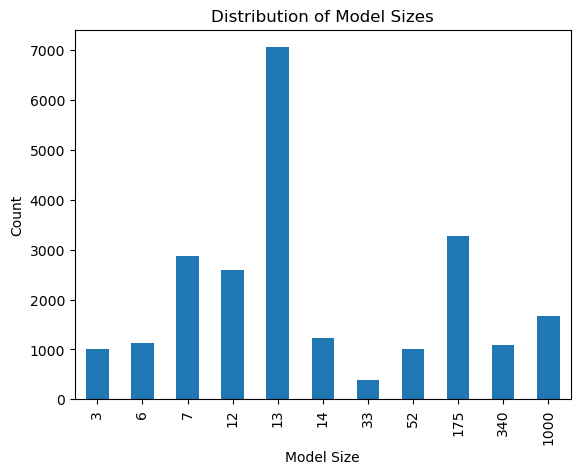

In [3]:
MODEL_SIZE = {
    "chatglm-6b": 6,
    "oasst-pythia-12b": 12,
    "koala-13b": 13,
    "vicuna-13b": 13,
    "stablelm-tuned-alpha-7b": 7,
    "alpaca-13b": 13,
    "llama-13b": 13,
    "dolly-v2-12b": 12,
    "fastchat-t5-3b": 3,
    "RWKV-4-Raven-14B": 14,
    "mpt-7b-chat": 7,
    "vicuna-7b": 7,
    "wizardlm-13b": 13,
    "gpt4all-13b-snoozy": 13,
    "guanaco-33b": 33,
    "gpt-3.5-turbo": 175,
    "gpt-4": 1000,
    "claude-v1": 175,
    "claude-instant-v1": 52,
    "palm-2": 340,
}

df["model_size_a"] = df["model_a"].apply(lambda x: MODEL_SIZE.get(x, np.nan))
df["model_size_b"] = df["model_b"].apply(lambda x: MODEL_SIZE.get(x, np.nan))

df["model_size_a"].value_counts().sort_index().plot(kind="bar", title="Distribution of Model Sizes")
plt.xlabel("Model Size")
plt.ylabel("Count")
plt.show()

## Model Sources

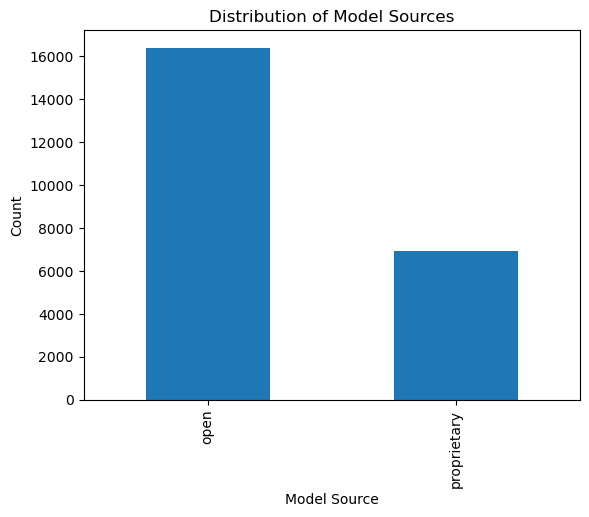

In [4]:
MODEL_SOURCE = {
    "chatglm-6b": "open",
    "oasst-pythia-12b": "open",
    "koala-13b": "open",
    "vicuna-13b": "open",
    "stablelm-tuned-alpha-7b": "open",
    "alpaca-13b": "open",
    "llama-13b": "open",
    "dolly-v2-12b": "open",
    "fastchat-t5-3b": "open",
    "RWKV-4-Raven-14B": "open",
    "mpt-7b-chat": "open",
    "vicuna-7b": "open",
    "wizardlm-13b": "open",
    "gpt4all-13b-snoozy": "open",
    "guanaco-33b": "open",
    "gpt-3.5-turbo": "proprietary",
    "gpt-4": "proprietary",
    "claude-v1": "proprietary",
    "claude-instant-v1": "proprietary",
    "palm-2": "proprietary",
}

df["model_source_a"] = df["model_a"].apply(lambda x: MODEL_SOURCE.get(x, np.nan))
df["model_source_b"] = df["model_b"].apply(lambda x: MODEL_SOURCE.get(x, np.nan))

df["model_source_b"].value_counts().sort_index().plot(kind="bar", title="Distribution of Model Sources")
plt.xlabel("Model Source")
plt.ylabel("Count")
plt.show()

## Model Organizations

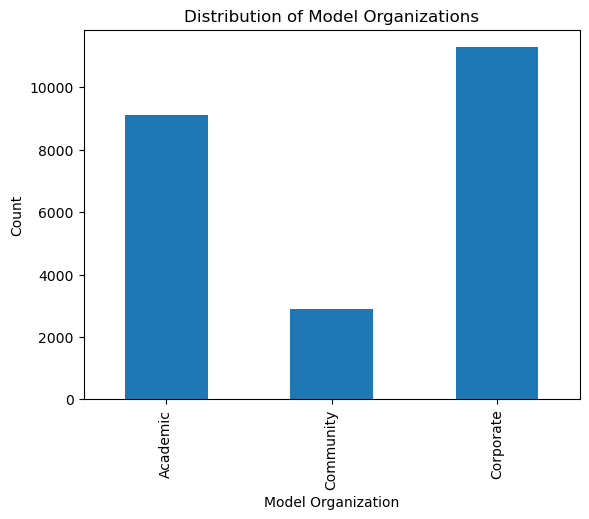

In [6]:
MODEL_ORG = {
    # --- CORPORATE (Big Tech & Companies) ---
    "gpt-3.5-turbo": "Corporate",
    "gpt-4": "Corporate",
    "claude-v1": "Corporate",
    "claude-instant-v1": "Corporate",
    "palm-2": "Corporate",
    "llama-13b": "Corporate",            # Meta
    "wizardlm-13b": "Corporate",         # Microsoft
    "stablelm-tuned-alpha-7b": "Corporate", # Stability AI
    "dolly-v2-12b": "Corporate",         # Databricks
    "mpt-7b-chat": "Corporate",          # MosaicML
    "gpt4all-13b-snoozy": "Corporate",   # Nomic AI

    # --- ACADEMIC (Universities & Research Labs) ---
    "vicuna-13b": "Academic",            # UC Berkeley
    "vicuna-7b": "Academic",             # UC Berkeley
    "koala-13b": "Academic",             # UC Berkeley
    "alpaca-13b": "Academic",            # Stanford
    "chatglm-6b": "Academic",            # Tsinghua
    "guanaco-33b": "Academic",           # UW
    "fastchat-t5-3b": "Academic",        # LMSYS (Research Org)

    # --- COMMUNITY (Open Collectives & Non-Profits) ---
    "oasst-pythia-12b": "Community",     # LAION
    "RWKV-4-Raven-14B": "Community"      # RWKV Community
}


df["model_org_a"] = df["model_a"].apply(lambda x: MODEL_ORG.get(x, np.nan))
df["model_org_b"] = df["model_b"].apply(lambda x: MODEL_ORG.get(x, np.nan))

df["model_org_a"].value_counts().sort_index().plot(kind="bar", title="Distribution of Model Organizations")
plt.xlabel("Model Organization")
plt.ylabel("Count")
plt.show()

## Conversation Turns/Lengths Features

In [ ]:
a_feats = df["conversation_a"].progress_apply(convo_turn_length_features).apply(pd.Series)
a_feats = a_feats.add_suffix("_a")

b_feats = df["conversation_b"].progress_apply(convo_turn_length_features).apply(pd.Series)
b_feats = b_feats.add_suffix("_b")

df = pd.concat([df, a_feats, b_feats], axis=1)

* **`num_turns`**: The total count of messages exchanged in the conversation (sum of all user and assistant messages).
* **`num_user_turns`**: The number of times the user sent a message.
* **`num_assistant_turns`**: The number of times the assistant replied.
* **`avg_user_turn_len_tokens`**: The average length of a user's prompt (calculated as `total_user_tokens / num_user_turns`).
* **`avg_assistant_turn_len_tokens`**: The average length of an assistant's response (calculated as `total_assistant_tokens / num_assistant_turns`).

## Conversation Format Features

In [ ]:
print("Running LLM classification for A...")
a_fmt = run_parallel_format(df, "a", workers=200)
df = df.join(a_fmt)

print("Running LLM classification for B...")
b_fmt = run_parallel_format(df, "b", workers=200)
df = df.join(b_fmt)

df.to_csv("results/df_with_llm_extraction.csv", index=False)
df = pd.read_csv("results/df_with_llm_extraction.csv")

This script generates three binary formatting features—`any_code_blocks`, `any_bullets`, and `any_headings`—by employing a lightweight LLM to scan the assistant's response history for specific Markdown syntax. It aggregates the assistant's messages, truncates them for efficiency, and prompts the model to return a structured JSON object indicating the presence (`1`) or absence (`0`) of code fences, list items, or section headers.  By parallelizing these API calls across the dataset, the pipeline efficiently captures the "visual structure" of the model's output, enabling the downstream statistical model to measure how formatting choices influence user preference.

## Conversation Topic Features

### OpenAI Embeddings & K-means Clustering

In [ ]:
df = pd.read_csv("results/df_with_llm_extraction.csv")
df, embeddings, kmeans_model = run_topic_clustering(
    df=df,
    text_column="prompt",             
    n_clusters=25,                       
    embed_cache_path="test_embeds.npy", 
    save_embeddings_in_df=False        
)
df.to_csv("results/df_with_emb_topics.csv", index=False)
df = pd.read_csv("results/df_with_emb_topics.csv")

To generate embeddings, the code employs a cost-efficient pipeline that first checks for a local cache (`.npy` file) to avoid redundant API calls; if valid cache is missing, it extracts non-empty text from the specified dataframe column and processes it in batches using OpenAI's `text-embedding-3-large` model. These high-dimensional vector representations are then standardized into a NumPy array (filling empty entries with zero vectors) and saved locally, serving as the input for a K-Means algorithm which groups the semantic vectors into distinct clusters based on geometric proximity.

### Inertia Plot

Analyzing inertia for K in [5, 15, 25, 35, 45, 55, 65, 75, 85, 95]...


Inertia Sweep: 100%|██████████| 10/10 [00:20<00:00,  2.04s/it]


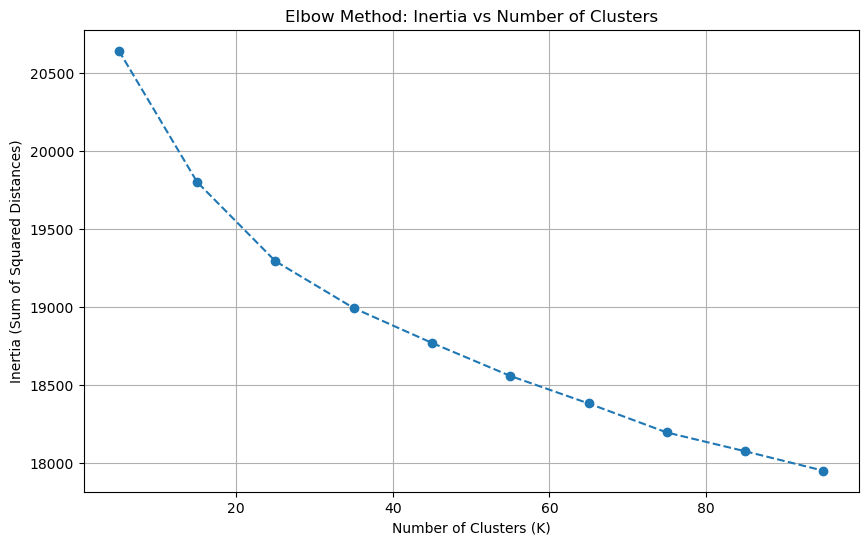

In [10]:
k_vals, inertias = analyze_inertia(
    embeddings, 
    k_min=5, 
    k_max=100, 
    step=10
)

### Cluster Centroids

In [11]:
archetypes = get_cluster_archetypes(df, embeddings, kmeans_model, "prompt", 30)

for cid, texts in list(archetypes.items())[:5]:
    for i, text in enumerate(texts[:5]):
        print(f"{text[:75]}...")
    print("-" * 40)
    print("\n\n\n\n")

Sprichst du deutsch ?...
Du bist Mark Breuer, ein Vertriebsmitarbeiter der Automaten Martin GmbH & C...
Könnt ihr auch deutsch anworten?...
Verstehst Du deutsch?...
Kannst du deutsch sprechen?...
----------------------------------------





1. A glass door has ‘push’ written on it in mirror writing. Should you push...
Finish this sentence in an amusing way: A B C D E...
Write a sentence without letters 'a' and 'e' in it...
Write 10 words semantically similar to up that are not similar to the words...
give examples of words that are five letters in length and do not use the s...
----------------------------------------





{\"role\":\"system\",\"content\":\"You are an assistent to a project manage...
"Create a prompt that encourages the model to adopt a personal assistant-li...
Take on the persona of a marketing professional. 

Research current trends ...
Okie dokie. You are an LLM. I am chatting simultaneously to you and to anot...
You are a Head of HR at a large tech company. Write 

### LLM Interpretation

In [12]:
cluster_labels = auto_label_clusters(archetypes, client)
for cid, label in cluster_labels.items():
    print(f"Cluster {cid}: {label}")

df["topic_name"] = df["topic_cluster"].map(cluster_labels).str.replace(" ", "_")
df.to_csv("results/df_with_emb_topics_explained.csv", index=False)
df = pd.read_csv("results/df_with_emb_topics_explained.csv")

Generating cluster labels...


100%|██████████| 25/25 [00:24<00:00,  1.04it/s]


Cluster 0: German language requests
Cluster 1: Word puzzles & prompts
Cluster 2: Diverse Prompt Examples
Cluster 3: Meaning of Life
Cluster 4: Technical Computer Science Topics
Cluster 5: Travel Itineraries
Cluster 6: Video game recommendations
Cluster 7: French language requests
Cluster 8: Logic Puzzles
Cluster 9: Large Language Models
Cluster 10: Python Code Requests
Cluster 11: Code Generation Requests
Cluster 12: Poetry Requests
Cluster 13: Requests to Write Stories
Cluster 14: Artificial Intelligence Questions
Cluster 15: Random playful questions
Cluster 16: US Presidents & Leadership
Cluster 17: Space & Astronomy
Cluster 18: Chatbot roleplay prompts
Cluster 19: Spanish Banking Assistant
Cluster 20: Greeting: How are you?
Cluster 21: Sexualized Roleplay Requests
Cluster 22: Personal improvement & activities
Cluster 23: Arithmetic Calculations
Cluster 24: Joke Requests


To interpret the clusters, we first identified the mathematical "archetypes" of each topic by finding the unique conversations closest to each K-Means cluster centroid, ensuring they represented the purest signal of that topic rather than edge cases.  These representative samples were then fed into an LLM with a strict prompt to extract a concise, human-readable label (e.g., "Python Debugging" or "Creative Writing"), effectively converting abstract vector groups into semantic categories that explain the specific user intent driving each conversation.

# Bayesian Modeling

## Feature Preprocessing

In [18]:
numeric_cols = [
    "model_size",
    "num_turns",
    "num_user_turns",
    "num_assistant_turns",
    "avg_user_turn_len_tokens",
    "avg_assistant_turn_len_tokens"
]

binary_cols = [
    "any_code_blocks",
    "any_bullets",
    "any_headings",
]

categorical_cols = [
    "model_org",
    "model_source",
]


def get_side_features(df, side):
    prefix = f"_{side}" if side in ["a", "b"] else ""

    data = {}


    for col in numeric_cols:
        data[col] = df[f"{col}_{side}"].values

    for col in binary_cols:
        data[col] = df[f"{col}_{side}"].values.astype(float)

    return pd.DataFrame(data)

combined_orgs = pd.concat([df["model_org_a"], df["model_org_b"]], axis=0)
combined_sources = pd.concat([df["model_source_a"], df["model_source_b"]], axis=0)

org_dummies = pd.get_dummies(combined_orgs, prefix="org", drop_first=True)
source_dummies = pd.get_dummies(combined_sources, prefix="source", drop_first=True)

n = len(df)
org_dummies_a = org_dummies.iloc[:n].reset_index(drop=True)
org_dummies_b = org_dummies.iloc[n:].reset_index(drop=True)

source_dummies_a = source_dummies.iloc[:n].reset_index(drop=True)
source_dummies_b = source_dummies.iloc[n:].reset_index(drop=True)

X_a_numeric = get_side_features(df, "a").reset_index(drop=True)
X_b_numeric = get_side_features(df, "b").reset_index(drop=True)

X_a_df = pd.concat([X_a_numeric, org_dummies_a, source_dummies_a], axis=1)
X_b_df = pd.concat([X_b_numeric, org_dummies_b, source_dummies_b], axis=1)

feature_names = X_a_df.columns.tolist()

scaler = StandardScaler()
X_stacked = pd.concat([X_a_df, X_b_df], axis=0)
scaler.fit(X_stacked)

X_a_scaled = scaler.transform(X_a_df)
X_b_scaled = scaler.transform(X_b_df)

X_diff = X_a_scaled - X_b_scaled

valid_idx = df["winner"].isin(["model_a", "model_b"])
X_final = X_diff[valid_idx]
y_final = (df.loc[valid_idx, "winner"] == "model_a").astype(int).values

topic_dummies = pd.get_dummies(df["topic_name"]).astype(float).values
topic_names = pd.get_dummies(df["topic_name"]).columns.tolist()


X_interaction_3d = np.einsum('ij,ik->ijk', X_final, topic_dummies)

N_samples = X_interaction_3d.shape[0]
X_crossed = X_interaction_3d.reshape(N_samples, -1)

crossed_feature_names = []
for topic in topic_names:
    for feature in feature_names:
        crossed_feature_names.append(f"{feature}__in__{topic}")

## Baseline Model

In [ ]:
with pm.Model() as simple_model:
    
    alpha = pm.Normal("alpha", mu=0, sigma=1.0) 
    beta = pm.Normal("beta", mu=0, sigma=1.0, shape=X_final.shape[1])
    
    mu = alpha + pm.math.dot(X_final, beta)
    y_obs = pm.Bernoulli("y_obs", logit_p=mu, observed=y_final)
    
    trace = pm.sample(
        tune=2000,           
        draws=2000,
        chains=4, 
        target_accept=0.9,
        nuts_sampler="numpyro"
    )

### Pooled Bayesian Logistic Regression

This model estimates a single global coefficient vector $\beta$ and intercept $\alpha$ to predict win probability, assuming that feature effects are universal and do not vary by topic.

$$\text{logit}(p) = \alpha + X \cdot \beta$$

Where:
* $p$ is the probability of Model A winning.
* $\beta$ represents the global impact of each feature (e.g., "Logic Score") on winning.
* $\alpha$ captures any baseline bias (e.g., positional advantage).

In [17]:
summary = az.summary(trace, var_names=["beta"], kind="stats", hdi_prob=0.95)
summary.index = feature_names
sigfins = summary[((summary["hdi_2.5%"] > 0) & (summary["hdi_97.5%"] > 0))
                  | ((summary["hdi_2.5%"] < 0) & (summary["hdi_97.5%"] < 0))]


print(sigfins[["mean", "hdi_2.5%", "hdi_97.5%"]].sort_values(by="mean", ascending=False).head(20))

                                mean  hdi_2.5%  hdi_97.5%
source_proprietary             0.725     0.688      0.761
avg_assistant_turn_len_tokens  0.423     0.390      0.458
model_size                     0.190     0.156      0.221
any_bullets                    0.132     0.104      0.161
any_code_blocks                0.126     0.088      0.165
org_Community                 -0.121    -0.141     -0.099
org_Corporate                 -0.295    -0.325     -0.267


### 1. The "Closed Source" Moat is Massive (`source_proprietary`: +0.725)
* **Interpretation:** Even after accounting for length, formatting, and size, **being a Proprietary model (GPT-4, Claude, Gemini)** is the single biggest predictor of winning. The "secret sauce" of their RLHF and pre-training data provides a massive advantage ($e^{0.725} \approx 2.1\times$ odds) over open-source models.

### 2. The "Verbosity" Rule Holds (`avg_assistant_turn_len_tokens`: +0.423)
* **Interpretation:** Brevity is generally punished. If a model wants to win in the general arena, it should error on the side of being comprehensive rather than concise.

### 3. Formatting: Bullets & Code Helps ( `any_bullets` +0.132 and `any_code_blocks` +0.126)
* **Interpretation:** Users like visual breaks (lists, code boxes) but don't care as much about structural segmentation (headings) in the global context. Headings might feel too "formal" for casual chats, cancelling out their benefit in structured tasks.

## Interaction Model (Baseline Features & Topics)

In [ ]:
with pm.Model() as interaction_model:

    alpha = pm.Normal("alpha", mu=0, sigma=1.0) 
    beta = pm.Normal("beta", mu=0, sigma=0.5, shape=X_crossed.shape[1])
    mu = alpha + pm.math.dot(X_crossed, beta)
    y_obs = pm.Bernoulli("y_obs", logit_p=mu, observed=y_final)
    
    trace = pm.sample(tune=2000,
                      draws=2000,
                      chains=4, 
                      target_accept=0.9,
                      nuts_sampler="numpyro")

### Crossed-Feature Bayesian Logistic Regression

This model extends the baseline by introducing **interaction terms** (crossing features with topics) to estimate context-specific strategies, allowing the "rules of winning" to vary depending on the topic.

$$\text{logit}(p) = \alpha + (X \times \text{Topic}) \cdot \beta$$

Where:
* $p$ is the probability of Model A winning.
* $\beta$ represents the **topic-specific** impact of each feature (e.g., "Logic Score *in* Politics" vs. "Logic Score *in* Creative Writing").
* $\alpha$ captures the global baseline bias (e.g., positional advantage).
* $X \times \text{Topic}$ is the expanded feature matrix where each original feature is multiplied by the one-hot encoded topic vector.

In [20]:
summary = az.summary(trace, var_names=["beta"], kind="stats", hdi_prob=0.95)
summary.index = crossed_feature_names
sigfins = summary[((summary["hdi_2.5%"] > 0) & (summary["hdi_97.5%"] > 0))
                  | ((summary["hdi_2.5%"] < 0) & (summary["hdi_97.5%"] < 0))]


print(sigfins[["mean", "hdi_2.5%", "hdi_97.5%"]].sort_values(by="mean", ascending=False).head(10))
print("\n")
print("-"*60)
print("\n")
print(sigfins[["mean", "hdi_2.5%", "hdi_97.5%"]].sort_values(by="mean", ascending=True).head(10))

                                                     mean  hdi_2.5%  hdi_97.5%
source_proprietary__in__US_Presidents_&_Leadership  1.142     0.927      1.369
org_Corporate__in__Word_puzzles_&_prompts           0.914     0.613      1.205
num_assistant_turns__in__Video_game_recommendat...  0.830     0.695      0.968
num_turns__in__Word_puzzles_&_prompts               0.828     0.640      1.024
org_Community__in__Video_game_recommendations       0.824     0.658      0.992
source_proprietary__in__Word_puzzles_&_prompts      0.823     0.657      0.984
model_size__in__Word_puzzles_&_prompts              0.815     0.605      1.035
any_code_blocks__in__Word_puzzles_&_prompts         0.803     0.573      1.030
num_user_turns__in__Video_game_recommendations      0.792     0.643      0.947
num_turns__in__Video_game_recommendations           0.778     0.590      0.961


------------------------------------------------------------


                                                     mean  hdi_2.5

While this interaction model captures some highly logical topic-specific behaviors, it also exhibits distinct signs of statistical noise and overfitting. On the logical side, it correctly identifies that **Proprietary models dominate factual, sensitive topics** like *US Presidents* (+1.142) but **lose significantly in *Sexualized Roleplay*** (-0.553), almost certainly because their strict safety filters cause them to refuse prompts that uncensored open-source models happily answer. 

However, the results become "noisy" in categories like *Word Puzzles* and *Video Game Recommendations*, where usually weak features (like `org_Community`) suddenly show massive positive spikes (+0.824) and turn-count metrics fluctuate wildly
